
# Avocado Prices adathalmaz elemzése

**A kutatás során ezekre a kérdésekre keressük a válaszokat.**

1. **Mennyire jelezhető előre az avokádó ára trend, szezonalitás és régiós eltérések alapján, és mely időszakokban romlik el látványosan az előrejelzés?** *(Három egyszerű módszerrel becsüljük meg a hagyományos avokádó következő heti árát.)*


2. **Mekkora a bioavokádó felára, és mennyire állandó a régiók és az évek között?** *(Ugyanazon a héten és ugyanabban a régióban hasonlítjuk össze a két árat. A különbséget dollárban és százalékban is megadjuk.)*


3. **Mennyire mozog együtt a hagyományos és a bioavokádó ára?** *(Megnézzük, hasonló időszakokban drága-e a két típus, és azt is, hogy egyik hétről a másikra általában azonos irányba változik-e az áruk.)*


## Adatok értelmezése és előkészítése:

**Forrás:** Justin Kiggins *Avocado Prices* adathalmazát használom, amely a **Hass Avocado Board** amerikai bolti eladási adatain alapul. Egy sorban egy piac, heti avokádi eladási adati vannak (usd/db ár, bio e ?, méret, milyen kiszerelésben) Az adatok 2015 januárjától 2018 márciusái tartanak.

Egy sor egy adott hét, terület és avokádótípus adatait tartalmazza. A `region` oszlopban városi piacok, nagyobb régiók és a `TotalUS` országos összesítés is szerepel.

### Adathalmaz változói:

| Változó | Magyarázat | Példa (első sor értékei) |
|---|---|---:|
| `Date` | A megfigyelési hét, ez mindig vasárnap. | `2015-12-27` |
| `region` | A piac vagy területi neve (állam is lehet, több várost egybefogó piac, vagy régiós összesítés). | `Albany` |
| `type` | Típus. `conventional` = hagyományos, `organic` = bio. | `conventional` |
| `year` | Külön eltárolva év. | `2015` |
| `AveragePrice` | Avokádó átlagos eladási ára, (usd/db). | 1,33 |
| `Total Volume` | Adott piacon, a teljes eladott mennyiség (minden méretből és zacskóból). | 64 236,62 |
| `4046` | Kis méretű, darabonként értékesített mennyiség. | 1 036,74 |
| `4225` | Nagy méretű, darabonként értékesített mennyiség. | 54 454,85 |
| `4770` | Extra nagy méretű, darabonként értékesített mennyiség. | 48,16 |
| `Total Bags` | Zacskós kiszerelésben értékesített összes mennyiség. | 8 696,87 |
| `Small Bags` | Kis zacskós kiszerelésben mennyiség. | 8 603,62 |
| `Large Bags` | Nagy zacskós kiszerelésben mennyiség. | 93,25 |
| `XLarge Bags` | Extra nagy zacskós kiszerelésben mennyiség. | 0 |
| `Unnamed: 0` | A CSV-be mentett régi sorindex, az értékei ismétlődnek, az elemzésből elhagyható. | 0 |

Először ellenőrizzük, hogy minden héthez van-e adat, és előfordul-e, hogy ugyanaz a hét, régió és típus kétszer szerepel. Átnézzük az árak tartományát is. A CSV-ben lévő `Unnamed: 0` csak sorszám, ezért eltávolítjuk.

In [3]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from matplotlib import dates as mdates
from sklearn.linear_model import LinearRegression

DATA_PATH = Path("data/avocado.csv")
raw = pd.read_csv(DATA_PATH, parse_dates=["Date"])
data = raw.drop(columns=["Unnamed: 0"], errors="ignore")
data = data.sort_values(["region", "type", "Date"]).reset_index(drop=True)

plt.rcParams.update({
    "figure.dpi": 115,
    "font.size": 10,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.titleweight": "bold",
    "axes.axisbelow": True,
    "grid.alpha": 0.25,
    "legend.frameon": False,
})
BLUE, ORANGE, TEAL, GRAY = "#22558a", "#b34a21", "#13766d", "#5b6574"
MONTH_NAMES = ["Jan.", "Febr.", "Márc.", "Ápr.", "Máj.", "Jún.",
               "Júl.", "Aug.", "Szept.", "Okt.", "Nov.", "Dec."]

print(f"Adatforrás: {DATA_PATH} | eredeti méret: {raw.shape[0]:,} sor, {raw.shape[1]} oszlop")
print(f"Időszak: {data['Date'].min():%Y-%m-%d} – {data['Date'].max():%Y-%m-%d}")
print(f"Területi címkék: {data['region'].nunique()} | különböző hetek: {data['Date'].nunique()}")
display(data.head(10))
display(data[["AveragePrice"]].describe().round(2))

Adatforrás: data/avocado.csv | eredeti méret: 18,249 sor, 14 oszlop
Időszak: 2015-01-04 – 2018-03-25
Területi címkék: 54 | különböző hetek: 169


,Date,AveragePrice,Total Volume,4046,4225,4770,Total Bags,Small Bags,Large Bags,XLarge Bags,type,year,region
0,2015-01-04,1.22,40873.28,2819.50,28287.42,49.90,9716.46,9186.93,529.53,0.0,conventional,2015,Albany
1,2015-01-11,1.24,41195.08,1002.85,31640.34,127.12,8424.77,8036.04,388.73,0.0,conventional,2015,Albany
2,2015-01-18,1.17,44511.28,914.14,31540.32,135.77,11921.05,11651.09,269.96,0.0,conventional,2015,Albany
3,2015-01-25,1.06,45147.50,941.38,33196.16,164.14,10845.82,10103.35,742.47,0.0,conventional,2015,Albany
4,2015-02-01,0.99,70873.60,1353.90,60017.20,179.32,9323.18,9170.82,152.36,0.0,conventional,2015,Albany
5,2015-02-08,0.99,51253.97,1357.37,39111.81,163.25,10621.54,10113.10,508.44,0.0,conventional,2015,Albany
6,2015-02-15,1.06,41567.62,986.66,30045.51,222.42,10313.03,9979.87,333.16,0.0,conventional,2015,Albany
7,2015-02-22,1.07,45675.05,1088.38,35056.13,151.00,9379.54,9000.16,379.38,0.0,conventional,2015,Albany
8,2015-03-01,0.99,55595.74,629.46,45633.34,181.49,9151.45,8986.06,165.39,0.0,conventional,2015,Albany
9,2015-03-08,1.07,40507.36,795.68,30370.64,159.05,9181.99,8827.55,354.44,0.0,conventional,2015,Albany


,AveragePrice
count,18249.00
mean,1.41
std,0.40
min,0.44
25%,1.10
50%,1.37
75%,1.66
max,3.25


,Darab
Hiányzó cellák,0
Ismétlődő hét–régió–típus kulcsok,0
Hiányzó hét–régió–típus kombinációk,3
Vasárnaptól eltérő dátumok,0
Eltérések a dátum és az év között,0
Nulla vagy negatív árak,0


,Date,region,type
0,2015-12-06,WestTexNewMexico,organic
1,2017-06-18,WestTexNewMexico,organic
2,2017-06-25,WestTexNewMexico,organic


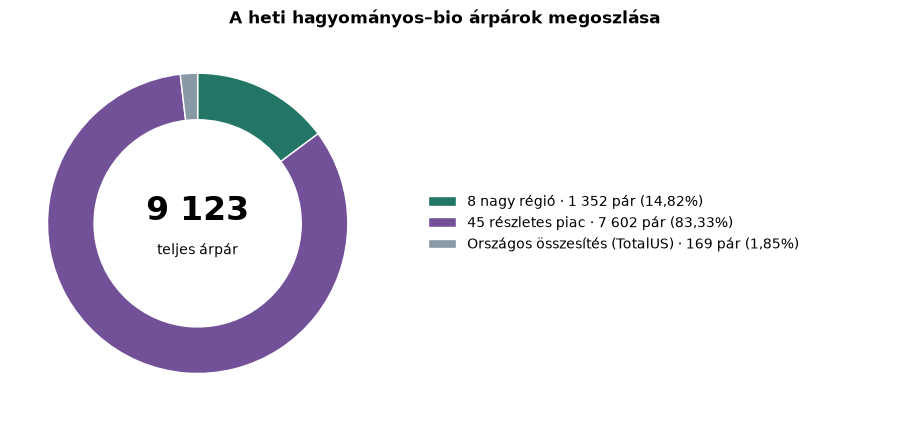

type,conventional,organic
Év,,
2015,52,52
2016,52,52
2017,53,53
2018,12,12


In [ ]:
import pandas as pd
from IPython.display import display

if "data" not in globals():
    data = (
        pd.read_csv("data/avocado.csv", parse_dates=["Date"])
        .drop(columns=["Unnamed: 0"], errors="ignore")
        .sort_values(["region", "type", "Date"])
        .reset_index(drop=True)
    )

KEY = ["Date", "region", "type"]
calendar_weeks = pd.date_range(data["Date"].min(), data["Date"].max(), freq="W-SUN")
expected = pd.MultiIndex.from_product(
    [calendar_weeks, sorted(data["region"].unique()), sorted(data["type"].unique())],
    names=KEY,
)
observed = pd.MultiIndex.from_frame(data[KEY])
missing_rows = expected.difference(observed)

checks = pd.Series({
    "Hiányzó cellák": data.isna().sum().sum(),
    "Ismétlődő hét–régió–típus kulcsok": data.duplicated(KEY).sum(),
    "Hiányzó hét–régió–típus kombinációk": len(missing_rows),
    "Vasárnaptól eltérő dátumok": data["Date"].dt.dayofweek.ne(6).sum(),
    "Eltérések a dátum és az év között": data["Date"].dt.year.ne(data["year"]).sum(),
    "Nulla vagy negatív árak": data["AveragePrice"].le(0).sum(),
}, name="Darab")
display(checks.to_frame())
display(missing_rows.to_frame(index=False))

import matplotlib.pyplot as plt

# Egy pár ugyanannak a területnek és hétnek a hagyományos és bio ára.
arparok = data.pivot(
    index=["Date", "region"], columns="type", values="AveragePrice"
).dropna(subset=["conventional", "organic"]).reset_index()

regios = arparok["region"].isin(SELECTED_REGIONS)
orszagos = arparok["region"].eq("TotalUS")

parok_szama = {
    "8 nagy régió": regios.sum(),
    "45 részletes piac": (~regios & ~orszagos).sum(),
    "Országos összesítés (TotalUS)": orszagos.sum(),
}
osszes_par = len(arparok)

fig, (ax, jelmagyarazat) = plt.subplots(
    1, 2, figsize=(9.2, 4.1), width_ratios=[1, 1.16],
    layout="constrained",
)
fig.suptitle("A heti hagyományos–bio árpárok megoszlása", fontweight="bold")

szeletek, _ = ax.pie(
    list(parok_szama.values()),
    startangle=90, counterclock=False,
    colors=["#237666", "#725199", "#8a99a6"],
    wedgeprops={"width": 0.31, "edgecolor": "white"},
)
ax.text(0, 0.08, f"{osszes_par:,}".replace(",", " "),
        ha="center", va="center", fontsize=24, fontweight="bold")
ax.text(0, -0.18, "teljes árpár", ha="center", va="center")

feliratok = []
for nev, darab in parok_szama.items():
    db = f"{darab:,}".replace(",", " ")
    szazalek = f"{100 * darab / osszes_par:.2f}%".replace(".", ",")
    feliratok.append(f"{nev} · {db} pár ({szazalek})")

jelmagyarazat.axis("off")
jelmagyarazat.legend(szeletek, feliratok, loc="center left", frameon=False)
plt.show()

display(data.groupby(["year", "type"])["Date"].nunique().unstack()
        .rename_axis(index="Év"))

A fájl meglévő soraiban nincsenek üres cellák, és minden hét/régió/típus kombináció egyszer szerepel. Három héten, a `WestTexNewMexico` bio avokádójáról teljesen hiányzik a sor.

Mivel az adathalmazban vannak adatok amelyek államokhoz, több várost összefogó piacokhoz vagy nagyobb több államot összefogó régiókhoz tartoznak. Mivel ha államonként öszesítem az adatok van három hét amikor hiányoznak az értékek és ha piaconként az pedig nem fed le akkora területet így a nyolc nagy régiót választottam ki a három vizsgálathoz, mert így nem kall adatokat pótólnom. Ezekben a régiókban mindkét típus ára mind a 169 hétre megvan, így azonos időszakokat tudunk vizsgálni. A régiók egyforma súlyt kapnak az átlagokban. Kalifornia azért kerül be a nyolc régióba, mert a régió  az adatforrás jelentési egységét jelenti. Tehát hiába külön állam kalifornia, az adathalmaz régióként kezeli. Az elemzés szempontjából pedig kaliforniával együtt a nyolc régió lefedi a teljes egyesült államokat. 

Az országos árat közvetlenül a fájl `TotalUS` soraiból olvassuk ki, mert ez a teljes amerikai kiskereskedelmi eladások összesítése.

A számítások alapja a heti ár. Néhány ábrán hónapok szerint foglaljuk össze a heteket, hogy könnyebb legyen felismerni a mintákat. Egy hét ahhoz a hónaphoz tartozik, amelyikbe a vasárnapja esik. A 2018-as adatok márciusig tartanak. A teljes éveket összehasonlító ábrák ezért 2015-től 2017-ig tartanak.


## 1. Kérdés: Mennyire jelezhető előre a következő heti ár?

**Három dolgot keresünk az ábrákon:**
* **Trend:** *(merre tart az ár hosszabb idő alatt)*
* **Szezonalitás:** *(az év hasonló részében újra megjelenik egy minta)*
* **Régiós eltérés:** *(egy területen általában drágább, mint egy másikon)*

**Ábrák felépítése:**
Az első ábrán a **szürke vonal** a heti országos ár, a **kék vonal** az adott és a megelőző 12 hét átlaga, amely kisimítja a rövid ingadozásokat. Az alsó ábrán a teljes évek havi átlagait tessük egymás mellé. A régiós árszinteket 2015 és 2016 adataiból számoljuk, mert a modellek is ezt a két évet kapják meg a tanuláshoz.

> **Megjegyzés:** Most csak a **hagyományos avokádó** árakkal dolgozunk.


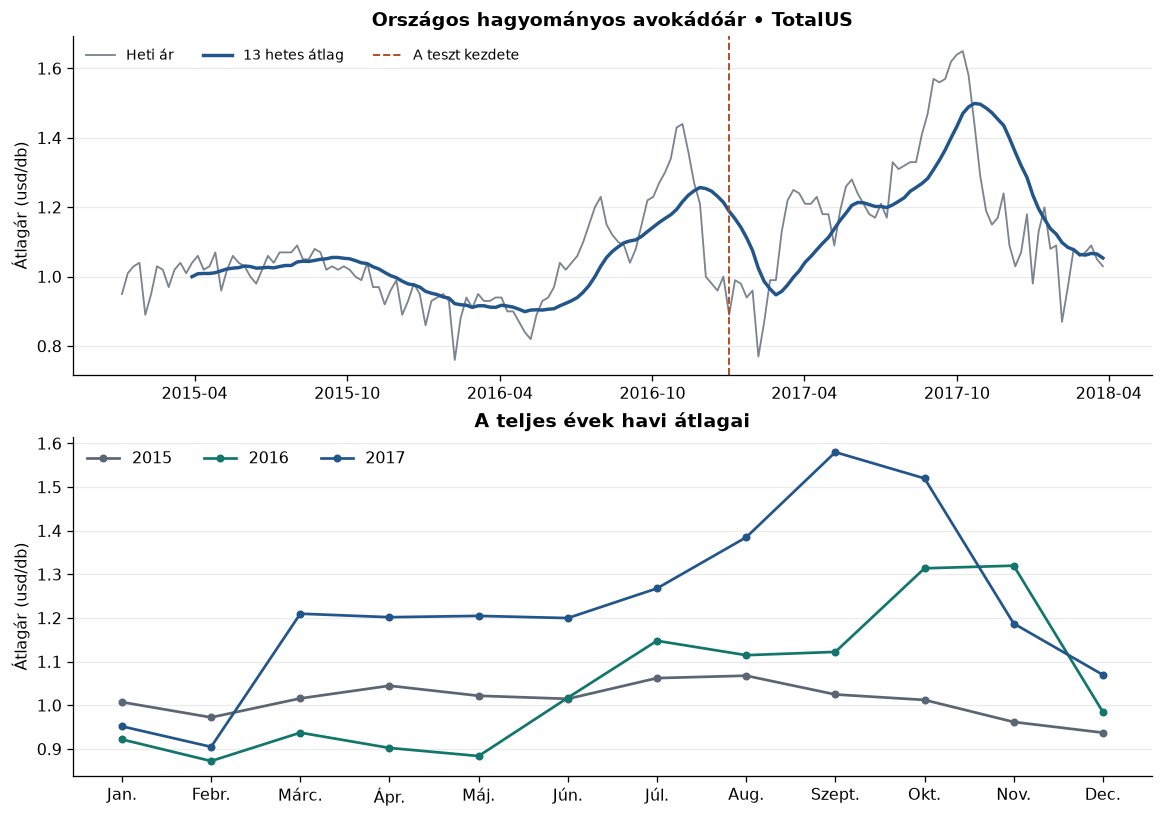

,Hetek,Átlag (usd),Minimum (usd),Maximum (usd)
Év,,,,
2015,52,1.012,0.89,1.09
2016,52,1.047,0.76,1.44
2017,53,1.222,0.77,1.65
2018,12,1.060,0.87,1.20


In [5]:
cutoff = pd.Timestamp("2017-01-01")
national = (
    data.loc[data["region"].eq("TotalUS") & data["type"].eq("conventional")]
    .set_index("Date")["AveragePrice"]
    .sort_index()
)
monthly_national = national.groupby([national.index.month, national.index.year]).mean().unstack()

fig, axes = plt.subplots(2, 1, figsize=(10, 7), layout="constrained")
axes[0].plot(national, color=GRAY, lw=1.15, alpha=0.80, label="Heti ár")
axes[0].plot(national.rolling(13).mean(), color=BLUE, lw=2.15, label="13 hetes átlag")
axes[0].axvline(cutoff, color=ORANGE, ls="--", lw=1.2, label="A teszt kezdete")
axes[0].set(title="Országos hagyományos avokádóár • TotalUS", ylabel="Átlagár (usd/db)")
axes[0].xaxis.set_major_locator(mdates.MonthLocator(interval=6))
axes[0].xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m"))
axes[0].legend(loc="upper left", ncol=3, fontsize=9)

for year, color in zip([2015, 2016, 2017], [GRAY, TEAL, BLUE]):
    axes[1].plot(monthly_national.index, monthly_national[year], marker="o",
                 ms=4, lw=1.7, label=str(year), color=color)
axes[1].set(title="A teljes évek havi átlagai", ylabel="Átlagár (usd/db)")
axes[1].set_xticks(range(1, 13), MONTH_NAMES)
axes[1].legend(loc="upper left", ncol=3)
for ax in axes:
    ax.grid(axis="y")
plt.show()

annual_price = national.groupby(national.index.year).agg(["size", "mean", "min", "max"])
display(annual_price.set_axis(["Hetek", "Átlag (usd)", "Minimum (usd)", "Maximum (usd)"], axis=1)
        .rename_axis("Év").round(3))

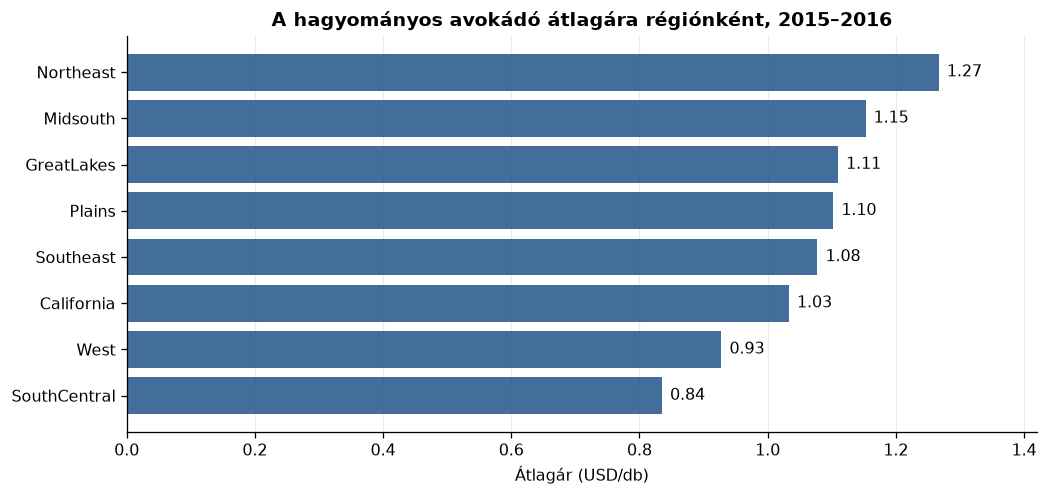

In [6]:
weekly = regional.loc[regional["type"].eq("conventional")].sort_values(["region", "Date"]).copy()
early = weekly.loc[weekly["Date"].lt(cutoff)]
early_prices = early.groupby("region")["AveragePrice"].mean().sort_values()
fig, ax = plt.subplots(figsize=(9, 4.2), layout="constrained")
bars = ax.barh(early_prices.index, early_prices, color=BLUE, alpha=0.85)
ax.bar_label(bars, fmt="%.2f", padding=5)
ax.set(title="A hagyományos avokádó átlagára régiónként, 2015–2016",
       xlabel="Átlagár (USD/db)", xlim=(0, 1.42))
ax.grid(axis="x")
plt.show()

2015 és 2017 között az éves átlag 1,01 usd-ről 1,22 usd-re növekedett. A heti ár közben többször hirtelen emelkedett, majd csökkent. 2017 azeptemberében elérte a 165 usd-t, aztán visszaesett az emelkedés előtti árfolyam alá. Az éves átlag mutat egy drégulást vagy van egy trend, de a heti árak hirtelen ugráltak fel-le.

Az őszi drágulás  2016-ban és 2017-ben is látszik. 2016-ban a legdrágább hónap  november, 2017-ben pedig szeptember volt. 2015-ben viszont nincsenek ekkora árváltozások, sokkal kiegyensúlyozottabb volt az év. Tehát az ősz több évben is drágább volt de a drágulás ideje és mértéke változott.

A régiós ábrán `SouthCentral` átlagára körülbelül 0,84 dollár, `Northeast` átlaga 1,27 dollár. Mivel nagy külömbségek vannak az átlagárakban ezért a közös alapár egy alacsonyabb átlagárú régiónál könnyen magasabb árat becsülne, egy magas átlagárúnál pedig alacsony árat becsülne. Ezért minden régió saját alapárszintet kap.




### Heti előrejelzések és időrendi teszt

- A modellek **2015–2016** adataiból tanulnak.
- A teszt **2017. január 1-től 2018. március 25-ig** tart.
- Mindig **egyetlen héttel** nézünk előre. (Például január második hetének becsléséhez január első hetének már ismert árát felhasználhatjuk.)
- A két tanított modellt a teszt alatt **nem tanítjuk újra**.
- Minden heti becsléshez csak olyan árakat használunk, amelyeket az adott hét előtt **már ismerhettünk**.

| Módszer | A becslés alapja |
|---|---|
| `Naiv` | Megismétli az adott régió előző heti árát. (Pl: ha az avokádó múlt héten 1,20 dollár volt, most is 1,20 dollárt becsül.) |
| `Trend + hónap + régió` | Figyelembe veszi, hogy hosszabb távon merre változik az ár, szeptemberben például mennyivel szokott drágább lenni, és milyen árszint jellemző az adott régióra. |
| `Trend + hónap + régió + előző hét` | Az előző modell mellé megkapja a régió legfrissebb ismert árát is. |

A két tanított modell lineáris regressziót használ. Az alapárhoz hozzáadja vagy abból levonja az idő, a hónap és a régió alapján becsült összeget. A harmadik modellbe az előző heti ár is beleszámít.

In [7]:
NAIVE = "Naiv"
CALENDAR = "Trend + hónap + régió"
WITH_LAG = "Trend + hónap + régió + előző hét"

weekly["week"] = (weekly["Date"] - weekly["Date"].min()).dt.days // 7
weekly["month"] = weekly["Date"].dt.month
weekly[NAIVE] = weekly.groupby("region")["AveragePrice"].shift(1)

month_flags = pd.get_dummies(weekly["month"], prefix="month", drop_first=True, dtype=int)
region_flags = pd.get_dummies(weekly["region"], prefix="region", drop_first=True, dtype=int)
features = pd.concat([weekly[["week", NAIVE]], month_flags, region_flags], axis=1)

calendar_columns = ["week", *month_flags.columns, *region_flags.columns]
specifications = {
    CALENDAR: calendar_columns,
    WITH_LAG: [*calendar_columns, NAIVE],
}
train_mask = weekly["Date"].lt(cutoff) & weekly[NAIVE].notna()
test_mask = weekly["Date"].ge(cutoff)
for name, columns in specifications.items():
    regression = LinearRegression()
    regression.fit(features.loc[train_mask, columns], weekly.loc[train_mask, "AveragePrice"])
    weekly.loc[test_mask, name] = regression.predict(features.loc[test_mask, columns])

model_names = [NAIVE, *specifications]
test = weekly.loc[test_mask].copy()
assert test[model_names].notna().all().all()
print(f"Tanító sorok: {train_mask.sum()} | tesztsorok: {len(test)}")
print(f"Közös tesztidőszak: {test['Date'].min():%Y-%m-%d} – {test['Date'].max():%Y-%m-%d}")
print(f"Teszthetek: {test['Date'].nunique()} | régiók: {test['region'].nunique()}")

Tanító sorok: 824 | tesztsorok: 520
Közös tesztidőszak: 2017-01-01 – 2018-03-25
Teszthetek: 65 | régiók: 8



Mindhárom módszert ugyanazon az **520 teszteseten** mérjük össze (ez 65 hét, nyolc régió). Mindkét regresszió ugyanazt a **824 tanítósort** kapja. Régiónként az első hét kimarad a tanításból, mert ahhoz még nincs korábbi ár.

- **MAE:** azt mutatja meg, átlagosan mennyivel tévedtünk.

- **RMSE:** szintén az eltérést méri, de nagyobb súlyt ad a kiugróan rossz becsléseknek. Kiszámításához négyzetre emeljük a hibákat, átlagot számolunk, majd gyököt vonunk (a végeredmény itt is dollárban értendő).

- **Átlagos előjeles hiba:** megmutatja, merre tévedünk (A becsült árból kivonjuk a tényleges árat, majd átlagolunk. A negatív eredmény azt jelzi, hogy átlagosan túl alacsony árat becsültünk).

,MAE (USD/db),RMSE (USD/db),Átlagos előjeles hiba (USD/db)
Módszer,,,
Naiv,0.0847,0.1143,-0.0005
Trend + hónap + régió + előző hét,0.0894,0.1148,-0.0334
Trend + hónap + régió,0.1604,0.2123,-0.1119


,Naiv,Trend + hónap + régió,Trend + hónap + régió + előző hét
Régió • MAE (USD/db),,,
SouthCentral,0.0605,0.1002,0.0602
Northeast,0.0657,0.1665,0.0751
West,0.0703,0.1325,0.0741
Midsouth,0.0789,0.1249,0.0805
Plains,0.0903,0.1637,0.0963
Southeast,0.0998,0.2022,0.1100
California,0.1015,0.1971,0.1049
GreatLakes,0.1103,0.1957,0.1137


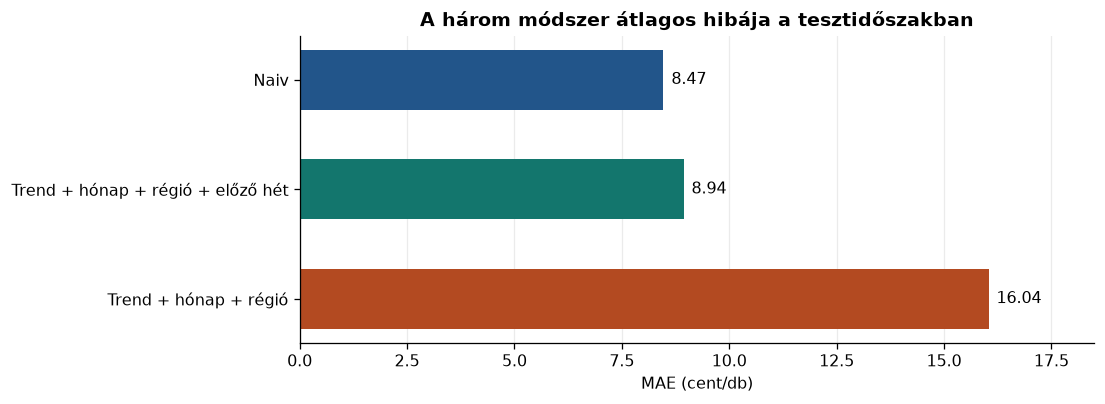

In [8]:
errors = test[model_names].sub(test["AveragePrice"], axis=0)
absolute_errors = errors.abs()
scores = pd.DataFrame({
    "MAE (USD/db)": absolute_errors.mean(),
    "RMSE (USD/db)": np.sqrt(errors.pow(2).mean()),
    "Átlagos előjeles hiba (USD/db)": errors.mean(),
}).sort_values("MAE (USD/db)")
display(scores.rename_axis("Módszer").round(4))

region_mae = absolute_errors.groupby(test["region"]).mean()
display(region_mae.sort_values(NAIVE).rename_axis("Régió • MAE (USD/db)").round(4))

model_colors = {NAIVE: BLUE, CALENDAR: ORANGE, WITH_LAG: TEAL}
fig, ax = plt.subplots(figsize=(9.5, 3.4), layout="constrained")
bars = ax.barh(scores.index, scores["MAE (USD/db)"] * 100,
               color=[model_colors[name] for name in scores.index], height=0.55)
ax.bar_label(bars, fmt="%.2f", padding=5)
ax.set(title="A három módszer átlagos hibája a tesztidőszakban",
       xlabel="MAE (cent/db)", xlim=(0, 18.5))
ax.invert_yaxis()
ax.grid(axis="x")
plt.show()


**Naiv:** Ez volt a legpontosabb, az előrejelzései átlagosan 8.47 centtel tértek el a valódi áraktól.

**Trend + hónap + régió:** átlagosan 16,04 centtel tévedet, mivel a korábbi évek árait követi és 2017-ben az árak jóval magasabbra kúsztak fel, ezért tévedett ekkorát.

**Trend + hónap + régió + előző hét:** átlagosan 8,94 centtel tévedt, ez azt jelenti, hogy majdnem 45%-ot javítottuk az előrejelzést az előzőhét árainak hozzáadásával.

> Az eredmények arra utalnak, hogy amikor változó mértékben növekednek vagy csökkennek az árak, az előző heti árak megadásável 45% kal pontosítható az előrejelzés. Viszont még így is a nyolc régióból, hétben a naiv módszer volt pontosabb.

A pontosság régiónként is változott. A naiv becslés a `SouthCentral` régióban átlagosan 6 centet, a `GreatLakes` régióban 11 centet tévedett. Ugyanattól a módszertől tehát egyik helyen pontosabb becslést kaptunk, mint a másikon.

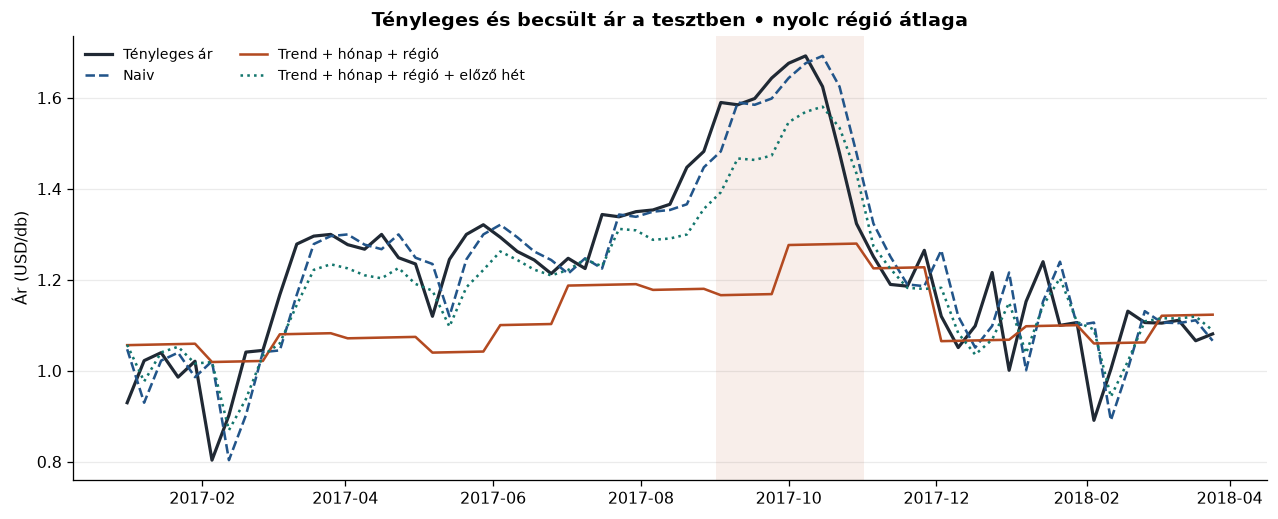

Naiv – a három legnagyobb heti MAE


,MAE (USD/db),Előjeles hiba (USD/db),Tényleges ár (USD/db),Becsült ár (USD/db)
Date,,,,
2017-02-05,0.2175,0.2175,0.8038,1.0212
2017-12-31,0.2150,0.2150,1.0012,1.2162
2018-02-04,0.2150,0.2150,0.8912,1.1062


Trend + hónap + régió – a három legnagyobb heti MAE


,MAE (USD/db),Előjeles hiba (USD/db),Tényleges ár (USD/db),Becsült ár (USD/db)
Date,,,,
2017-09-24,0.4750,-0.4750,1.6438,1.1688
2017-09-17,0.4308,-0.4308,1.5987,1.1680
2017-09-03,0.4236,-0.4236,1.5900,1.1664


Trend + hónap + régió + előző hét – a három legnagyobb heti MAE


,MAE (USD/db),Előjeles hiba (USD/db),Tényleges ár (USD/db),Becsült ár (USD/db)
Date,,,,
2017-02-05,0.2156,0.2156,0.8038,1.0193
2018-02-04,0.1997,0.1997,0.8912,1.0910
2017-09-03,0.1974,-0.1974,1.5900,1.3926


In [13]:
weekly_mae = absolute_errors.groupby(test["Date"]).mean()
weekly_signed = errors.groupby(test["Date"]).mean()
weekly_levels = test.groupby("Date")[["AveragePrice", *model_names]].mean()

fig, ax = plt.subplots(figsize=(11, 4.4), layout="constrained")
ax.plot(weekly_levels.index, weekly_levels["AveragePrice"], color="#202934",
        lw=2.0, label="Tényleges ár")

for name, style in zip(model_names, ["--", "-", ":"]):
    ax.plot(weekly_levels.index, weekly_levels[name], color=model_colors[name],
            lw=1.6, ls=style, label=name)

ax.axvspan(pd.Timestamp("2017-09-01"), pd.Timestamp("2017-11-01"),
           color=ORANGE, alpha=0.09, linewidth=0)
ax.set(title="Tényleges és becsült ár a tesztben • nyolc régió átlaga",
       ylabel="Ár (USD/db)")
ax.xaxis.set_major_locator(mdates.MonthLocator(interval=2))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m"))
ax.legend(loc="upper left", ncol=2, fontsize=8.5)
ax.grid(axis="y")
plt.show()

for name in model_names:
    worst_weeks = pd.DataFrame({
        "MAE (USD/db)": weekly_mae[name],
        "Előjeles hiba (USD/db)": weekly_signed[name],
        "Tényleges ár (USD/db)": weekly_levels["AveragePrice"],
        "Becsült ár (USD/db)": weekly_levels[name],
    })
    print(f"{name} – a három legnagyobb heti MAE")
    display(worst_weeks.nlargest(3, "MAE (USD/db)").round(4))


### Mikor romlott el látványosan az előrejelzés?

A heti táblázatok mindhárom modellnél azt a három hetet mutatják, amikor a becslés átlagosan a legtávolabb volt a tényleges ártól. A MAE megmutatja, mekkora volt a tévedés a nyolc régióban átlagosan. Az előjeles hiba az irányt is megadja. A pozitív érték túlbecslést, a negatív érték alulbecslést jelent. 

#### Naiv módszer

Mindhárom héten a valódi ár főlé jelzett. 2017. feb. 5-én volt a legnyobb tévedése, a nyolc átlagára kb 80 cent volt, az előrejelzésünk viszont 1,02 dollár. Tehát átlagosan kb 22 centettel jelzett magasabb árat. Ezek a tévedések annak tudthatóak be, hogy ez a módszer az előző heti áraakt ismétli, ez addig nagyon jó módszer amíg az árak csak kicsit változnak, de ezeken a kiemelt heteken hirteen sokkal olcsóbb lett az avokádó, ezért jelezett mindig magasabb árat. Viszont a teljes tesztben ez a módszer volt a legpontosabb.

#### Trend + hónap + régió

Ennél a modelnél mindhárom hét szeptemberre esett, és mindig a valódi ár alá jelzett. A legnagyobb eltérés 2017. szept. 24, az átlagár kb 1,64 dollár, a modell 1,17 dollárt jelzett előre. Ez kb 48 centes tévedés. és 3x akkora, mint a modell egész teszthalmazon számolt 16 centes átlagos hiibázása. Az ábrán jól látszik, hogy szeptemberben és októberben hatalmasat emelkedtek az árak, viszont e modell tanítóhalmazában nem voltak ekkora emelkedések, ezért a modell végig alacsonyabb árakat jelzett előre.

#### Trend + hónap + régió + előző hét

Az előző heti ár hozzáadása a modellhez így az előrejelzése sokkal pontosabb lett. 2017. szept. 3-án a valódi ár 1,6 dollár volt, az új modell 1,4 dollárt jelzett (az előző modell, az előző heti ár nélkül csak 1,17 dollárt jelzett). A tévedés így kb 20 centre csökkent. A hirtelen áreséseknél viszot ez a modell is nagyot tévedett. 2017. feb. 5-én átlagosan 22 centtel, 2018. feb. 4-én pedig 20 centtel jelzett magasabb árat. Ez a két hét benne volt a naivnál is a három legrosszabba, mert ha az ár hirtelen leesik, a múlt heti ár még attól a magasabb árszintet mutatja.

#### Következtetés

> A modellek két különböző helyzetben hibáztak látványosan. A trendet, hónapot és régiót használó modell 2017 szeptemberében több héten át lemaradt a drágulás mögött. Az előző heti árat is használó módszerek jobban követték ezt az emelkedést, viszont a hirtelen bekövetkezett áreséseknél továbbra is nagyot tévedtek. Az MAE alapján az előző heti ár megismétlése adta a legpontosabb előre jelzést. Az ábrából látszik, hogy amikor egy hirtelen emelkedés vagy esés történik a héten utána érdemes lazabban kezelni az előrejelzést mert megnől a hibázási aránya.

## 2. Kérdés: Mekkora a bioavokádó felára, és mennyire állandó?

### Azonos régió és hét összehasonlítása:

A nyolc kiválasztott régióban minden héthez megvan a hagyományos és bio ár is, így csinalunk párokat.

A felár azt mutatja, mennyivel kerül többe a bio.

**Felár számítása (bio-hagyományos):** 1,50 - 1 = 50 *(50 cent a felár vagy 50%)*

Az **átlag** mellé **mediánt** is számolunk, mert egyetlen drága hét felhúzza az átlagot, a medián viszont kevésbé érzékeny a szélső értékekre.

A mediánhoz sorba rendezzük a felárakat a legkisebbtől a legnagyobbig, majd kiválasztjuk a középsőt *(páros számú árnál a két középső átlaga adja a mediánt)*.

Összehasonlítható árpárok: 1,352
Dollárfelár átlaga: 0.482 USD/db
Dollárfelár mediánja: 0.490 USD/db
Százalékos felár mediánja: 45.16%
Bio drágább: 1319 pár (97.56%)
Azonos ár: 1 pár
Bio olcsóbb: 32 pár


,Párok,Átlag_USD,Medián_USD,Medián_százalék,Bio_drágább_százalék
region,,,,,
GreatLakes,169,0.313,0.35,30.556,89.349
Midsouth,169,0.395,0.42,34.454,95.858
Southeast,169,0.470,0.47,41.379,97.041
SouthCentral,169,0.464,0.48,56.667,100.000
Northeast,169,0.515,0.54,40.517,100.000
California,169,0.580,0.55,52.222,100.000
Plains,169,0.542,0.56,50.926,100.000
West,169,0.574,0.57,57.447,98.225


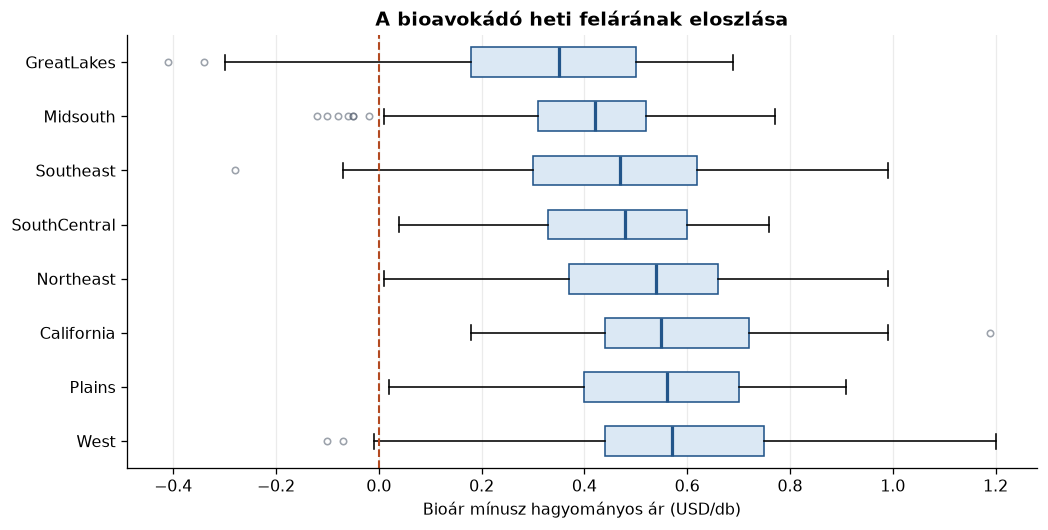

In [14]:
pairs = (
    regional.pivot(index=["Date", "region"], columns="type", values="AveragePrice")
    .dropna(subset=["organic", "conventional"])
    .reset_index()
)
pairs["premium_usd"] = pairs["organic"] - pairs["conventional"]
pairs["premium_pct"] = 100 * pairs["premium_usd"] / pairs["conventional"]
pairs["bio_higher"] = pairs["premium_usd"].gt(0)
pairs["year"] = pairs["Date"].dt.year

print(f"Összehasonlítható árpárok: {len(pairs):,}")
print(f"Dollárfelár átlaga: {pairs['premium_usd'].mean():.3f} USD/db")
print(f"Dollárfelár mediánja: {pairs['premium_usd'].median():.3f} USD/db")
print(f"Százalékos felár mediánja: {pairs['premium_pct'].median():.2f}%")
print(f"Bio drágább: {pairs['bio_higher'].sum()} pár ({100 * pairs['bio_higher'].mean():.2f}%)")
print(f"Azonos ár: {pairs['premium_usd'].eq(0).sum()} pár")
print(f"Bio olcsóbb: {pairs['premium_usd'].lt(0).sum()} pár")

premium_by_region = pairs.groupby("region").agg(
    Párok=("premium_usd", "size"),
    Átlag_USD=("premium_usd", "mean"),
    Medián_USD=("premium_usd", "median"),
    Medián_százalék=("premium_pct", "median"),
    Bio_drágább_százalék=("bio_higher", lambda values: 100 * values.mean()),
).sort_values("Medián_USD")
display(premium_by_region.round(3))

region_order = premium_by_region.index
fig, ax = plt.subplots(figsize=(9, 4.5), layout="constrained")
ax.boxplot(
    [pairs.loc[pairs["region"].eq(region), "premium_usd"] for region in region_order],
    orientation="horizontal", patch_artist=True, widths=0.55,
    boxprops={"facecolor": "#dbe8f4", "edgecolor": BLUE},
    medianprops={"color": BLUE, "linewidth": 2},
    flierprops={"marker": "o", "markersize": 4, "markeredgecolor": GRAY, "alpha": 0.6},
)
ax.set_yticks(range(1, len(region_order) + 1), region_order)
ax.axvline(0, color=ORANGE, ls="--", lw=1.3)
ax.set(title="A bioavokádó heti felárának eloszlása", xlabel="Bioár mínusz hagyományos ár (USD/db)")
ax.invert_yaxis()
ax.grid(axis="x")
plt.show()

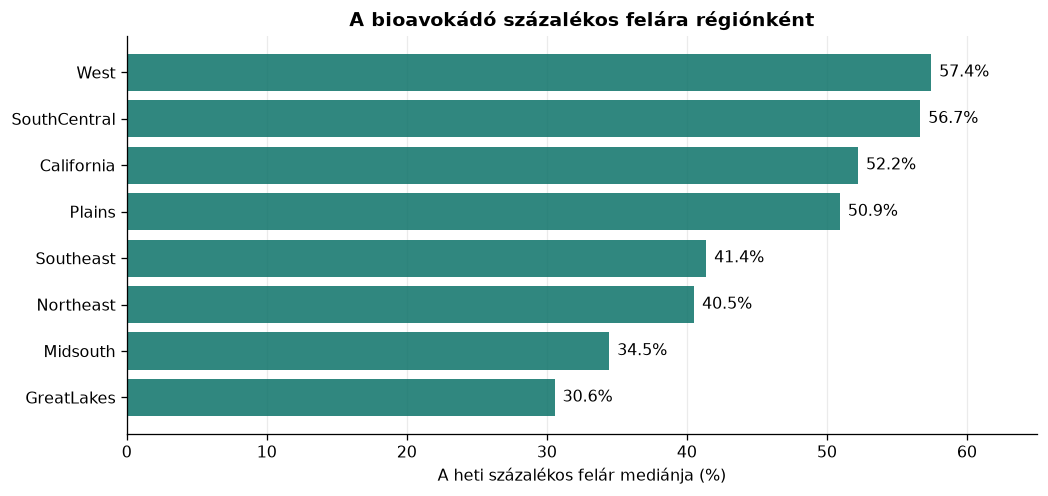

In [15]:
relative_premium = premium_by_region["Medián_százalék"].sort_values()
fig, ax = plt.subplots(figsize=(9, 4.2), layout="constrained")
bars = ax.barh(relative_premium.index, relative_premium, color=TEAL, alpha=0.88)
ax.bar_label(bars, fmt="%.1f%%", padding=5)
ax.set(title="A bioavokádó százalékos felára régiónként",
       xlabel="A heti százalékos felár mediánja (%)", xlim=(0, 65))
ax.grid(axis="x")
plt.show()

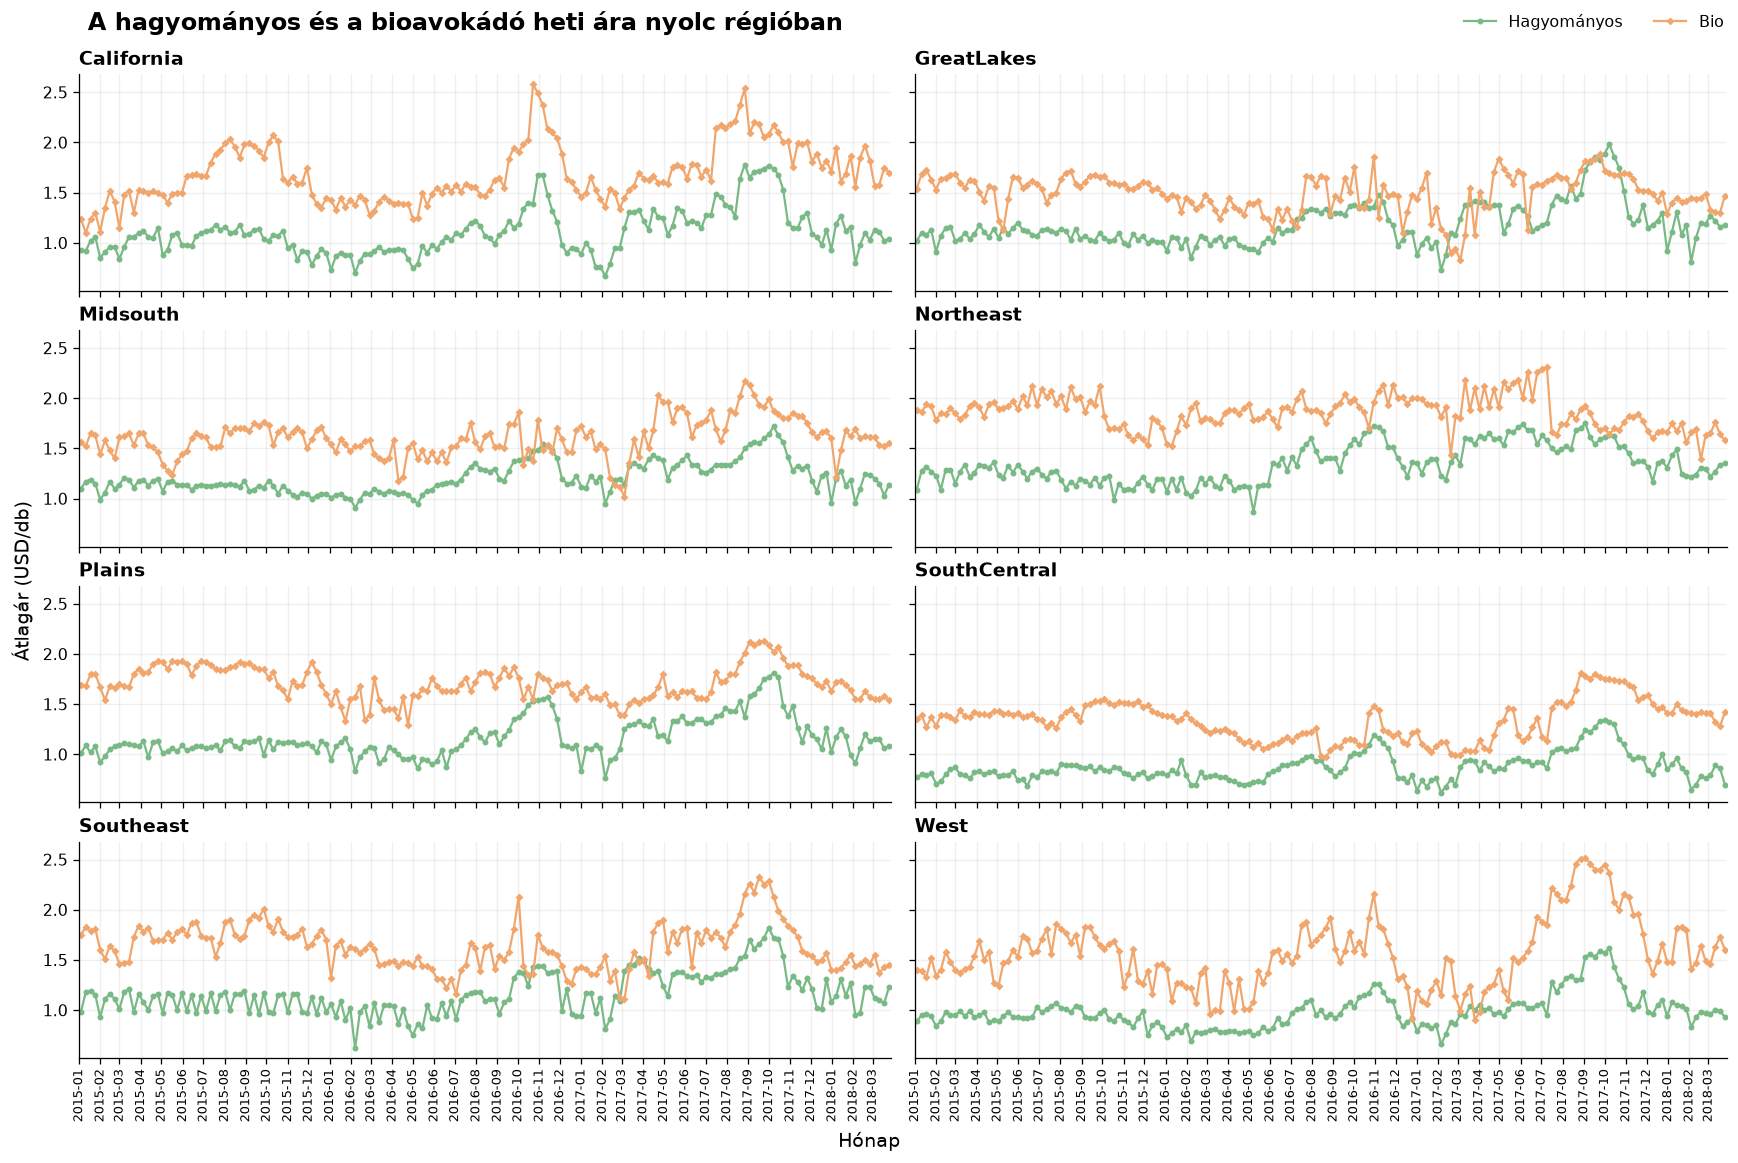

In [16]:
regional_prices = pairs.set_index(["region", "Date"])[["conventional", "organic"]].sort_index()

fig, axes = plt.subplots(
    4, 2, figsize=(15, 10), sharex=True, sharey=True, layout="constrained"
)

for ax, region in zip(axes.flat, SELECTED_REGIONS):
    prices = regional_prices.loc[region]
    ax.plot(prices.index, prices["conventional"], color="#78B985",
            marker="o", markersize=2.7, linewidth=1.4, label="Hagyományos")
    ax.plot(prices.index, prices["organic"], color="#F0A66D",
            marker="D", markersize=2.5, linewidth=1.4, label="Bio")
    ax.set_title(region, loc="left")
    ax.grid(alpha=0.20)

first_month = pairs["Date"].min().to_period("M").start_time
last_week = pairs["Date"].max()
axes[-1, 0].set_xlim(first_month, last_week + pd.Timedelta(days=3))
axes[-1, 0].xaxis.set_major_locator(mdates.MonthLocator())
axes[-1, 0].xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m"))

for ax in axes[-1]:
    ax.tick_params(axis="x", labelrotation=90, labelsize=8)

fig.suptitle("A hagyományos és a bioavokádó heti ára nyolc régióban",
             x=0.047, ha="left", fontsize=15, fontweight="bold")
fig.supylabel("Átlagár (USD/db)")
fig.supxlabel("Hónap")
handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc="outside upper right", ncol=2)
plt.show()

### Az árkülönbség régiónként

**1352 párból**, **1319-ben (kb 97%)** a bio volt a drágább és **32 esetben** a bio volt az olcsóbb, illetve egy párnál az árak megegyeztek. A **medián felár 49 cent (45%)**.

A **boxplot ábrán** minden sor egy régió. A boxban a középső vonal a medián a két széla az alsó és felső kvartilis. A függőleges vonal 0-nál van tehát amelyik tőle balra van ott a bio olcsóbb, jobbra drágább a hagyományosnál.

A **százalékos oszlopdiagram** más sorrendet ad mivel a medián százalék arányosan mondja meg a felárat. `SouthCentral` régióban a felár 48 cent, százalékban viszont 57%-ban volt magasabb a hagyományoshoz képest. Néhány esetben volt hogy a bio olcsóbb volt a hagyományosnál, 2017. márc. 5-én a `GreatLakes` régióban 1,24 dollár volt a hagyományos és csak 83 cent a bio. Ez - 41 cent felár a hagyományosra.

### Változott-e a felár az évek során?

Most megnézzük hogy adott hónapban mennyivel került többe a bio.

A felárat **évenként** is összehasonlítjuk. **2015, 2016 és 2017** esetében az **egész évet** nézzük. 2018-ból csak januártól márciusig vannak adataink, ezért külön összevetjük mind a négy év **első három hónapját**. Így 2018 elejét a korábbi évek azonos időszakához hasonlítjuk.

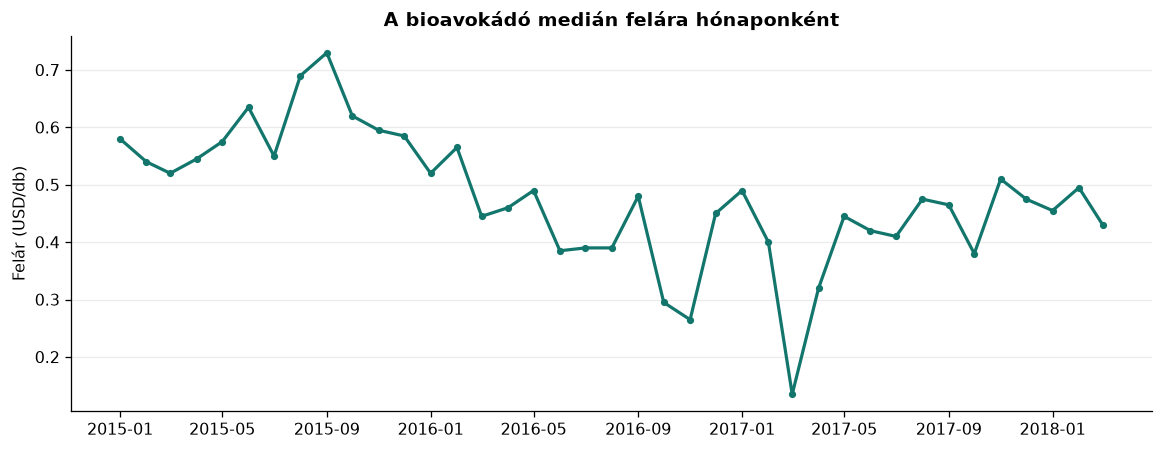

Teljes évek


,Párok,Medián_USD,Medián_százalék,Bio_drágább_százalék
Év,,,,
2015,416,0.590,57.303,99.760
2016,416,0.450,43.374,97.837
2017,424,0.425,33.208,94.575


Januártól márciusig


,Párok,Medián_USD,Medián_százalék,Bio_drágább_százalék
Év,,,,
2015,104,0.540,51.585,100.000
2016,104,0.520,53.042,100.000
2017,104,0.350,35.050,88.462
2018,96,0.455,39.469,100.000


In [18]:
monthly_premium = pairs.groupby(pairs["Date"].dt.to_period("M"))["premium_usd"].median()
fig, ax = plt.subplots(figsize=(10, 3.8), layout="constrained")
ax.plot(monthly_premium.index.to_timestamp(), monthly_premium, color=TEAL, lw=2, marker="o", ms=3.5)
ax.set(title="A bioavokádó medián felára hónaponként", ylabel="Felár (USD/db)")
ax.xaxis.set_major_locator(mdates.MonthLocator(interval=4))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m"))
ax.grid(axis="y")
plt.show()

full_years = pairs.loc[pairs["year"].isin([2015, 2016, 2017])]
first_quarter = pairs.loc[pairs["Date"].dt.month.le(3)]
period_summaries = {}
for title, subset in [("Teljes évek", full_years), ("Januártól márciusig", first_quarter)]:
    print(title)
    summary = subset.groupby("year").agg(
        Párok=("premium_usd", "size"),
        Medián_USD=("premium_usd", "median"),
        Medián_százalék=("premium_pct", "median"),
        Bio_drágább_százalék=("bio_higher", lambda values: 100 * values.mean()),
    ).rename_axis("Év")
    period_summaries[title] = summary
    display(summary.round(3))



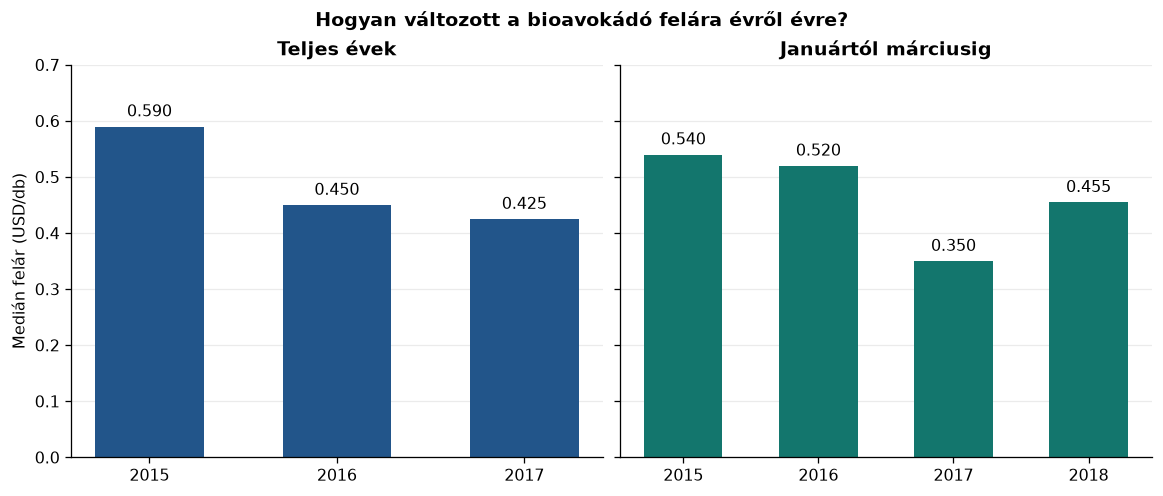

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4.2), sharey=True, layout="constrained")
for ax, (title, summary), color in zip(axes, period_summaries.items(), [BLUE, TEAL]):
    bars = ax.bar(summary.index.astype(str), summary["Medián_USD"], color=color, width=0.58)
    ax.bar_label(bars, fmt="%.3f", padding=4)
    ax.set(title=title, ylim=(0, 0.70))
    ax.grid(axis="y")
axes[0].set_ylabel("Medián felár (USD/db)")
fig.suptitle("Hogyan változott a bioavokádó felára évről évre?", fontweight="bold")
plt.show()

### Válasz a második kérdésre

A teljes évek medián felára **2015-ben 59 cent**, **2016-ban 45 cent**, **2017-ben 42,5 cent** volt. A százalékos felár mediánja közben 57,30%-ról 33,21%-ra csökkent. A havi ábrán ennél nagyobb mozgások is látszanak. A két szélső hónap2015 szeptembere 73 centtel és 2017 márciusa 13,5 centtel.

A **jan. - márc.-ig** tartó szakaszban a felár **2015-ben 54 cent**, **2016-ban 52 cent**, **2017-ben 35 cent**, **2018-ban 45,5 cent** volt. A bio szinte mindig drágább volt, de a felár régiónként és időszakonként is változott.

### Korlátok.

Ebben az elemzésben minden hétnek ugyan annyi a súlya, attól függetlenül, hogy egy héten mennyi avokádót adtak el. A bio és hagyományos árak ugyanabból a hétből és régióból származnak, de az avokűdók méretét és , hogy akciós volt e vagy nem, ezeket nem vettük figyelembe. A felár ezért a fájlban szereplő átlagárak közötti külömbséget mutatják.